# 05 Robustness: sub-periods and transaction costs

Owner: Ma Tianjiao (B3).

Both methods on the pre-registered bull and bear sub-periods and with a 0.1% cost per switch.

The main result (full sample, no costs) is re-run in three situations that were **fixed in the proposal before looking at the data**:

| case | data | block length $\ell = \text{round}(n^{1/3})$ |
|---|---|---|
| Bull market | 2020-01-01 to 2021-12-31 (731 days) | 9 |
| Bear market | 2022-01-01 to 2022-12-31 (365 days) | 7 |
| Full sample + 0.1% cost per switch | `d_cost`, 2,557 days | 14 |

Each case uses both methods, calling only `t_test_mean()` (B1) and Deng's `mbb_ci()` / `mbb_test()` (A3). Nothing is re-implemented here.

**Multiple testing.** Three extra tests raise the chance that at least one looks "significant" by luck (with 3 independent tests at 5%, about $1 - 0.95^3 \approx 14\%$). So these are robustness checks only; no separate conclusion is drawn from any single case.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

# Run from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config
from src.data import load_daily
from src.strategy import build_series

FIG_DIR = config.FIG_DIR
TAB_DIR = config.TAB_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Two fixed colours: blue = t-test, orange = block bootstrap
C_T, C_BOOT, C_GREY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
pd.options.display.float_format = "{:.6g}".format

rng = np.random.default_rng(config.SEED)

from src.classical import t_test_mean
from src.bootstrap import mbb_ci, mbb_test

**Config.** Everything here comes from `src/config.py`.

In [2]:
LEVEL = 1 - config.ALPHA
B = config.B                 # 9,999
BULL = config.SUB_PERIODS["bull_2020_2021"]
BEAR = config.SUB_PERIODS["bear_2022"]
DAYS_PER_YEAR = 365


def block_len(n):
    return int(round(n ** (1 / 3)))

## 1 · Cases

In [3]:
series = build_series(load_daily())

cases = {
    "Full sample (main result)": series["d"],
    "Bull 2020-2021": series.loc[BULL[0]:BULL[1], "d"],
    "Bear 2022": series.loc[BEAR[0]:BEAR[1], "d"],
    "Full sample + 0.1% cost": series["d_cost"],
}

for name, x in cases.items():
    print(f"{name:<28} n = {len(x):>5,}   l = {block_len(len(x))}")

assert len(cases["Bull 2020-2021"]) == 731
assert len(cases["Bear 2022"]) == 365

Full sample (main result)    n = 2,557   l = 14
Bull 2020-2021               n =   731   l = 9
Bear 2022                    n =   365   l = 7
Full sample + 0.1% cost      n = 2,557   l = 14


## 2 · Both methods in every case

In [4]:
rows = []
for name, x in cases.items():
    x = x.to_numpy()
    n, L = len(x), block_len(len(x))
    tt = t_test_mean(x, LEVEL)
    ci = mbb_ci(x, L, B, LEVEL)
    te = mbb_test(x, L, B)
    rows.append({"case": name, "method": "t-test", "n": n, "L": np.nan,
                 "d_bar": tt["mean"], "SE": tt["se"], "lo": tt["t_lo"], "hi": tt["t_hi"], "p": tt["p"]})
    rows.append({"case": name, "method": "block bootstrap", "n": n, "L": L,
                 "d_bar": ci["mean"], "SE": ci["se"], "lo": ci["pct_lo"], "hi": ci["pct_hi"], "p": te["p"]})

rob = pd.DataFrame(rows)
rob["d_bar (annualised)"] = rob["d_bar"] * DAYS_PER_YEAR
rob["95% CI"] = [f"[{lo:.5f}, {hi:.5f}]" for lo, hi in zip(rob["lo"], rob["hi"])]
rob.to_csv(TAB_DIR / "05_robustness.csv", index=False)
rob[["case", "method", "n", "L", "d_bar", "d_bar (annualised)", "SE", "95% CI", "p"]]

,case,method,n,L,d_bar,d_bar (annualised),SE,95% CI,p
0,Full sample (main result),t-test,2557,NaN,-0.000207795,-0.075845,0.00047466,"[-0.00114, 0.00072]",0.661586
1,Full sample (main result),block bootstrap,2557,14,-0.000207795,-0.075845,0.000415522,"[-0.00101, 0.00062]",0.6177
2,Bull 2020-2021,t-test,731,NaN,4.79611e-05,0.0175058,0.00115546,"[-0.00222, 0.00232]",0.966902
3,Bull 2020-2021,block bootstrap,731,9,4.79611e-05,0.0175058,0.0010226,"[-0.00179, 0.00218]",0.9644
4,Bear 2022,t-test,365,NaN,0.000729769,0.266366,0.00142893,"[-0.00208, 0.00354]",0.609863
5,Bear 2022,block bootstrap,365,7,0.000729769,0.266366,0.00146204,"[-0.00201, 0.00369]",0.6188
6,Full sample + 0.1% cost,t-test,2557,NaN,-0.000263747,-0.0962678,0.000474737,"[-0.00119, 0.00067]",0.578557
7,Full sample + 0.1% cost,block bootstrap,2557,14,-0.000263747,-0.0962678,0.000416652,"[-0.00107, 0.00056]",0.525


Consistency check: the full-sample rows must match notebook 02 (t-test) and notebook 03 (bootstrap, $\ell = 14$).

In [5]:
main = rob[rob["case"] == "Full sample (main result)"].set_index("method")
print(main[["n", "d_bar", "SE", "lo", "hi", "p"]])

                    n        d_bar          SE          lo          hi  \
method                                                                   
t-test           2557 -0.000207795  0.00047466 -0.00113855 0.000722964   
block bootstrap  2557 -0.000207795 0.000415522 -0.00101173 0.000616859   

                       p  
method                    
t-test          0.661586  
block bootstrap   0.6177  


## 3 · Interval plot

One row per case: point = $\bar d$, lines = the two 95% intervals.

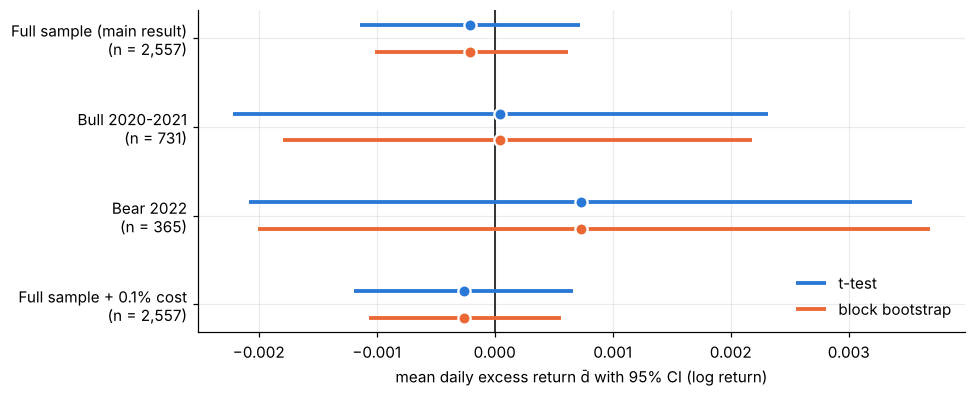

In [6]:
order = list(cases)
y = np.arange(len(order))
offset = {"t-test": -0.15, "block bootstrap": 0.15}
colour = {"t-test": C_T, "block bootstrap": C_BOOT}

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvline(0, color="black", lw=1)
for method in offset:
    sub = rob[rob["method"] == method].set_index("case").loc[order]
    yy = y + offset[method]
    ax.hlines(yy, sub["lo"], sub["hi"], color=colour[method], lw=2.5, label=method)
    ax.plot(sub["d_bar"], yy, "o", color=colour[method], ms=8, mec="white", mew=1.5)
ax.set_yticks(y, [f"{c}\n(n = {len(cases[c]):,})" for c in order])
ax.invert_yaxis()
ax.set_xlabel("mean daily excess return d̄ with 95% CI (log return)")
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG_DIR / "05_robustness_ci.png")
plt.show()

<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** No case changes the main conclusion: every interval from both methods contains 0, and every p-value is above 0.5.
The sign of $\bar d$ does change with the market state, as you would expect from a trend-following rule.
In the 2020–21 bull market the rule is invested on 62% of days and ends up with almost the same return as buy-and-hold ($\bar d \approx +0.00005$).
In the 2022 bear market it is invested on only 38% of days and sits out part of the decline, so $\bar d = +0.00073$ a day (about $+27\%$ a year). This is still nowhere near significant ($p \approx 0.61$).
The sub-period intervals are 2–3 times wider than the full-sample ones: $n$ drops from 2,557 to 731 and 365 (SE shrinks like $1/\sqrt n$), and 2020–22 was also the most volatile stretch.
Charging 0.1% per switch (143 switches in seven years) lowers $\bar d$ from $-0.00021$ to $-0.00026$ a day, about 2 percentage points a year, and the conclusion stays the same.
The sub-periods and the cost level were fixed in the proposal before the analysis, and three extra tests raise the chance of at least one false positive to about 14%. So this section is a robustness check only and draws no separate conclusion.